# The Renewal Wave: What Happens When a 2020 or 2021 Five Year Fixed Comes Due

**Author:** John Khan

**Question.** Canadians who took a five year fixed mortgage in 2020 and 2021 locked in the lowest rates on record. Those terms come up for renewal in 2025 and 2026. How big is the payment jump when they renew at the rates lenders were actually charging at renewal time?

**Approach.** Instead of a single made up borrower, I use the Bank of Canada's monthly series on the average rate charged on new five year fixed mortgages at chartered banks. Each month from January 2020 to December 2021 is a cohort. I take that month's rate as the rate at signing, and the rate exactly 60 months later as the rate at renewal. Where the renewal month is past the latest data, I use the latest month available and flag it.

**Data (live from the Bank of Canada Valet API, https://www.bankofcanada.ca/valet/docs):**

| Series ID | What it is |
|---|---|
| `V122667786` | Interest rate on new uninsured residential mortgages, fixed 5 years and over, chartered banks, monthly |
| `V122667780` | Same, insured mortgages |

Both come from the Bank of Canada table "Interest rates charged for new and existing lending by chartered banks" (group `A4_RATES_MORTGAGES`, https://www.bankofcanada.ca/?p=197471). If the API is down, the notebook reads the snapshot it saved in `data/`.

**Assumptions, stated plainly.** Payments use Canadian semi annual compounding, a 25 year amortization at signing, and the same payment schedule with 20 years left at renewal. The payment change in percent does not depend on loan size. The dollar figures use a $400,000 starting balance purely as an example, not as a typical or average loan.

In [1]:
import io, os, json
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

BLUE = "#011F5B"
RED = "#990000"

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#444444",
    "axes.grid": True,
    "grid.color": "#e6e6e6",
    "grid.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "legend.frameon": False,
})
TITLE_FONT = {"family": "serif", "weight": "bold", "size": 15}

VALET = "https://www.bankofcanada.ca/valet/observations/{ids}/json"
SNAPSHOT_DIR = "data"

def valet(series, start=None, snapshot=None):
    """Pull one or more Bank of Canada Valet series into a DataFrame.
    If the live pull fails, fall back to a CSV snapshot saved next to the notebook
    (on Kaggle, upload the snapshot CSV as a dataset and point SNAPSHOT_DIR at it)."""
    ids = ",".join(series)
    params = {"start_date": start} if start else {}
    try:
        r = requests.get(VALET.format(ids=ids), params=params, timeout=60)
        r.raise_for_status()
        obs = r.json()["observations"]
        rows = []
        for o in obs:
            row = {"date": o["d"]}
            for s in series:
                v = o.get(s, {}).get("v")
                row[s] = float(v) if v not in (None, "") else np.nan
            rows.append(row)
        df = pd.DataFrame(rows)
        df["date"] = pd.to_datetime(df["date"])
        df = df.set_index("date").sort_index()
        if snapshot:
            os.makedirs(SNAPSHOT_DIR, exist_ok=True)
            df.to_csv(os.path.join(SNAPSHOT_DIR, snapshot))
        print(f"Live pull OK: {ids} ({len(df)} rows, {df.index.min().date()} to {df.index.max().date()})")
        return df
    except Exception as e:
        path = os.path.join(SNAPSHOT_DIR, snapshot or "missing.csv")
        print(f"Live pull failed ({e}). Reading snapshot {path}")
        return pd.read_csv(path, index_col="date", parse_dates=True)

def style(ax, title, ylabel=None):
    ax.set_title(title, fontdict=TITLE_FONT, loc="left", color=BLUE)
    if ylabel:
        ax.set_ylabel(ylabel)
    return ax

def save(fig, name):
    os.makedirs("charts", exist_ok=True)
    fig.tight_layout()
    fig.savefig(os.path.join("charts", name), dpi=150, bbox_inches="tight")
    plt.show()


## 1. Pull the rates

In [2]:
r = valet(["V122667786", "V122667780"], snapshot="monthly_5yr_fixed_rates.csv")
r = r.rename(columns={"V122667786": "uninsured", "V122667780": "insured"}).dropna(how="all")
latest_month = r.dropna().index.max()
print("Latest month with data:", latest_month.strftime("%B %Y"))
r.loc["2020-01-01":"2021-12-01"].T.round(2)

Live pull OK: V122667786,V122667780 (163 rows, 2013-01-01 to 2026-07-01)
Latest month with data: July 2026


date,2020-01-01,2020-02-01,2020-03-01,2020-04-01,2020-05-01,2020-06-01,2020-07-01,2020-08-01,2020-09-01,2020-10-01,...,2021-03-01,2021-04-01,2021-05-01,2021-06-01,2021-07-01,2021-08-01,2021-09-01,2021-10-01,2021-11-01,2021-12-01
uninsured,2.97,2.96,2.78,2.71,2.69,2.6,2.46,2.26,2.15,2.05,...,1.96,2.03,2.11,2.14,2.28,2.31,2.33,2.22,2.35,2.51
insured,2.91,2.90,2.71,2.65,2.62,2.5,2.36,2.19,2.09,1.99,...,1.91,1.95,2.03,2.06,2.17,2.21,2.18,2.12,2.23,2.38


## 2. Payment math

In [3]:
def monthly_rate(annual_pct):
    """Canadian fixed mortgages compound semi annually."""
    return (1 + annual_pct / 100 / 2) ** (1 / 6) - 1

def payment(balance, annual_pct, months):
    i = monthly_rate(annual_pct)
    return balance * i / (1 - (1 + i) ** -months)

def balance_after(balance, annual_pct, months_total, months_paid):
    i = monthly_rate(annual_pct)
    pmt = payment(balance, annual_pct, months_total)
    return balance * (1 + i) ** months_paid - pmt * ((1 + i) ** months_paid - 1) / i

EXAMPLE_LOAN = 400_000   # example only
AMORT_MONTHS = 25 * 12
TERM_MONTHS = 60

# quick check against a hand calculation: 5.00% on 100,000 over 25 years is about 581.60 a month
print(round(payment(100_000, 5.0, 300), 2))

581.6


In [4]:
rows = []
for series in ["uninsured", "insured"]:
    for start in pd.date_range("2020-01-01", "2021-12-01", freq="MS"):
        renew = start + pd.DateOffset(months=TERM_MONTHS)
        actual = renew <= latest_month
        renew_used = renew if actual else latest_month
        r0 = r.loc[start, series]
        r1 = r.loc[renew_used, series]
        p0 = payment(EXAMPLE_LOAN, r0, AMORT_MONTHS)
        bal = balance_after(EXAMPLE_LOAN, r0, AMORT_MONTHS, TERM_MONTHS)
        p1 = payment(bal, r1, AMORT_MONTHS - TERM_MONTHS)
        rows.append({"series": series, "signed": start, "renews": renew, "renewal rate is actual": actual,
                     "rate at signing": r0, "rate at renewal": r1, "rate change": r1 - r0,
                     "balance at renewal": bal, "payment before": p0, "payment after": p1,
                     "payment change $": p1 - p0, "payment change %": (p1 / p0 - 1) * 100})
cohorts = pd.DataFrame(rows)
u = cohorts[cohorts.series == "uninsured"].set_index("signed")
show = u[["renews", "renewal rate is actual", "rate at signing", "rate at renewal", "payment before", "payment after", "payment change %"]].copy()
show["renews"] = show["renews"].dt.strftime("%b %Y")
show.round(2)

,renews,renewal rate is actual,rate at signing,rate at renewal,payment before,payment after,payment change %
signed,,,,,,,
2020-01-01,Jan 2025,True,2.97,4.59,1886.83,2170.40,15.03
2020-02-01,Feb 2025,True,2.96,4.61,1884.78,2173.61,15.32
2020-03-01,Mar 2025,True,2.78,4.52,1848.12,2149.76,16.32
2020-04-01,Apr 2025,True,2.71,4.30,1833.97,2107.40,14.91
2020-05-01,May 2025,True,2.69,4.24,1829.93,2095.89,14.53
2020-06-01,Jun 2025,True,2.60,4.25,1811.85,2093.92,15.57
2020-07-01,Jul 2025,True,2.46,4.27,1783.91,2091.58,17.25
2020-08-01,Aug 2025,True,2.26,4.31,1744.41,2090.13,19.82
2020-09-01,Sep 2025,True,2.15,4.37,1722.90,2095.97,21.65


## 3. Charts

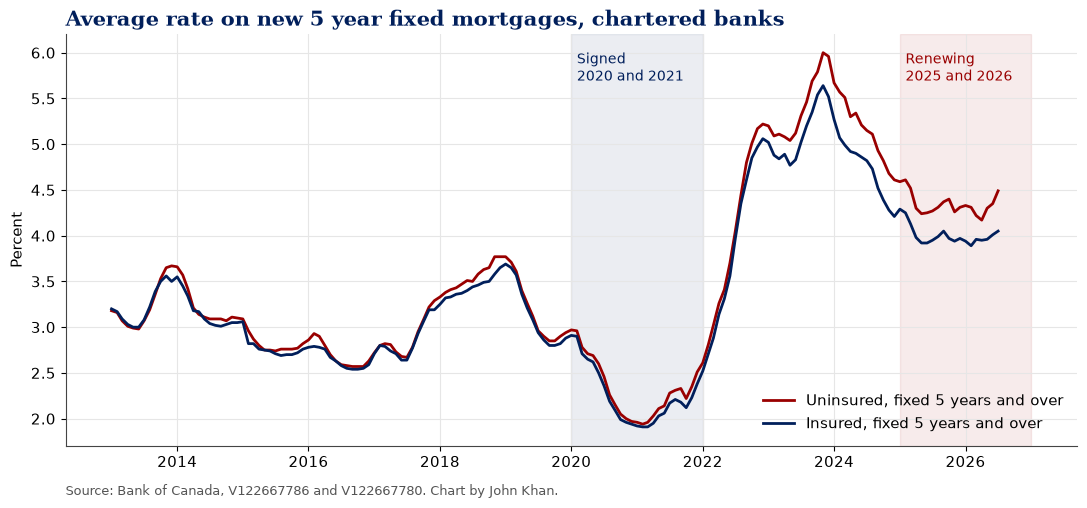

In [5]:
fig, ax = plt.subplots(figsize=(11, 5.2))
ax.plot(r.index, r["uninsured"], color=RED, lw=2, label="Uninsured, fixed 5 years and over")
ax.plot(r.index, r["insured"], color=BLUE, lw=2, label="Insured, fixed 5 years and over")
ax.axvspan(pd.Timestamp("2020-01-01"), pd.Timestamp("2021-12-31"), color=BLUE, alpha=0.08)
ax.axvspan(pd.Timestamp("2025-01-01"), pd.Timestamp("2026-12-31"), color=RED, alpha=0.08)
ax.text(pd.Timestamp("2020-02-01"), ax.get_ylim()[1] * 0.97, "Signed\n2020 and 2021", va="top", color=BLUE, fontsize=10)
ax.text(pd.Timestamp("2025-02-01"), ax.get_ylim()[1] * 0.97, "Renewing\n2025 and 2026", va="top", color=RED, fontsize=10)
style(ax, "Average rate on new 5 year fixed mortgages, chartered banks", "Percent")
ax.legend(loc="lower right")
ax.text(0, -0.12, "Source: Bank of Canada, V122667786 and V122667780. Chart by John Khan.", transform=ax.transAxes, fontsize=9, color="#555555")
save(fig, "01_rates_signing_vs_renewal.png")

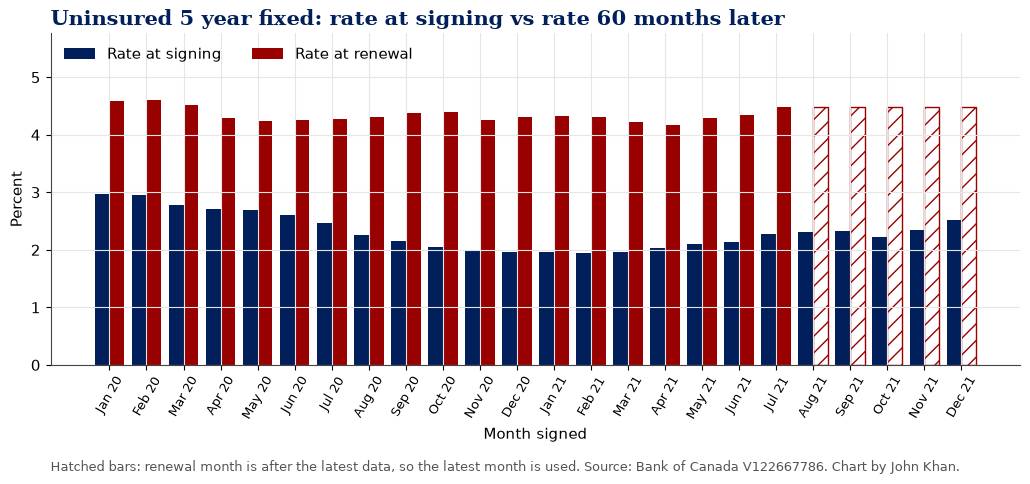

In [6]:
fig, ax = plt.subplots(figsize=(11, 5.2))
x = np.arange(len(u))
w = 0.4
ax.bar(x - w / 2, u["rate at signing"], w, color=BLUE, label="Rate at signing")
ax.bar(x + w / 2, u["rate at renewal"], w, color=RED, label="Rate at renewal")
for i, (ok) in enumerate(u["renewal rate is actual"]):
    if not ok:
        ax.bar(x[i] + w / 2, u["rate at renewal"].iloc[i], w, color="white", edgecolor=RED, hatch="//", lw=1)
ax.set_xticks(x)
ax.set_xticklabels([d.strftime("%b %y") for d in u.index], rotation=60, fontsize=9)
style(ax, "Uninsured 5 year fixed: rate at signing vs rate 60 months later", "Percent")
ax.set_ylim(0, u["rate at renewal"].max() * 1.25)
ax.set_xlabel("Month signed")
ax.legend(loc="upper left", ncol=2)
ax.text(0, -0.32, "Hatched bars: renewal month is after the latest data, so the latest month is used. Source: Bank of Canada V122667786. Chart by John Khan.",
        transform=ax.transAxes, fontsize=9, color="#555555")
save(fig, "02_cohort_rates.png")

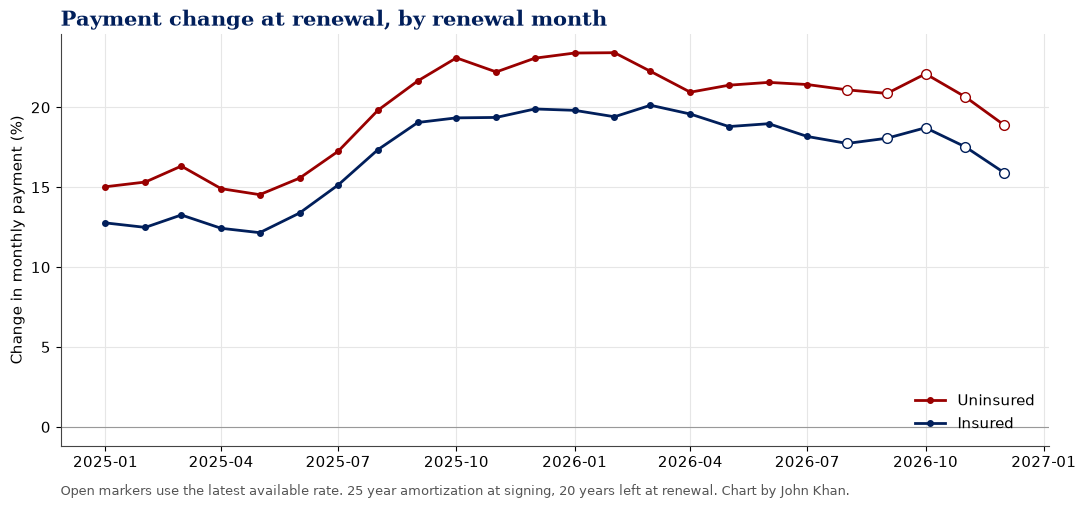

In [7]:
fig, ax = plt.subplots(figsize=(11, 5.2))
for series, color in [("uninsured", RED), ("insured", BLUE)]:
    s = cohorts[cohorts.series == series].set_index("renews")
    ax.plot(s.index, s["payment change %"], color=color, lw=2, marker="o", ms=4, label=series.capitalize())
    est = s[~s["renewal rate is actual"]]
    ax.plot(est.index, est["payment change %"], ls="none", marker="o", ms=7, mfc="white", mec=color)
ax.axhline(0, color="#999999", lw=0.8)
style(ax, "Payment change at renewal, by renewal month", "Change in monthly payment (%)")
ax.legend(loc="lower right")
ax.text(0, -0.12, "Open markers use the latest available rate. 25 year amortization at signing, 20 years left at renewal. Chart by John Khan.",
        transform=ax.transAxes, fontsize=9, color="#555555")
save(fig, "03_payment_change_pct.png")

## 4. The numbers behind the conclusion

In [8]:
for series in ["uninsured", "insured"]:
    s = cohorts[cohorts.series == series]
    a = s[s["renewal rate is actual"]]
    print(f"--- {series} ({len(a)} cohorts with an actual renewal rate, renewing {a.renews.min().strftime('%b %Y')} to {a.renews.max().strftime('%b %Y')})")
    print(f"  rate at signing: low {s['rate at signing'].min():.2f}% ({s.loc[s['rate at signing'].idxmin(), 'signed'].strftime('%b %Y')}), high {s['rate at signing'].max():.2f}%")
    print(f"  rate at renewal (actual): {a['rate at renewal'].min():.2f}% to {a['rate at renewal'].max():.2f}%")
    print(f"  payment change, actual cohorts: median {a['payment change %'].median():.1f}%, min {a['payment change %'].min():.1f}%, max {a['payment change %'].max():.1f}%")
    big = a.loc[a['payment change %'].idxmax()]
    print(f"  biggest jump: signed {big.signed.strftime('%b %Y')} at {big['rate at signing']:.2f}%, renewed {big.renews.strftime('%b %Y')} at {big['rate at renewal']:.2f}%: "
          f"{big['payment change %']:.1f}%, on the $400k example ${big['payment before']:,.0f} to ${big['payment after']:,.0f} (+${big['payment change $']:,.0f})")
    print(f"  example: median dollar change on the $400k example loan: +${a['payment change $'].median():,.0f} a month")
    e = s[~s["renewal rate is actual"]]
    if len(e):
        print(f"  cohorts still to renew ({e.renews.min().strftime('%b %Y')} to {e.renews.max().strftime('%b %Y')}), at the latest rate {e['rate at renewal'].iloc[0]:.2f}%: "
              f"{e['payment change %'].min():.1f}% to {e['payment change %'].max():.1f}%")
    print(f"  balance left after 5 years on the example loan: about {s['balance at renewal'].median() / EXAMPLE_LOAN * 100:.0f}% of the original")

--- uninsured (19 cohorts with an actual renewal rate, renewing Jan 2025 to Jul 2026)
  rate at signing: low 1.94% (Feb 2021), high 2.97%
  rate at renewal (actual): 4.17% to 4.61%
  payment change, actual cohorts: median 21.4%, min 14.5%, max 23.4%
  biggest jump: signed Feb 2021 at 1.94%, renewed Feb 2026 at 4.31%: 23.4%, on the $400k example $1,682 to $2,076 (+$394)
  example: median dollar change on the $400k example loan: +$367 a month
  cohorts still to renew (Aug 2026 to Dec 2026), at the latest rate 4.49%: 18.9% to 22.1%
  balance left after 5 years on the example loan: about 84% of the original
--- insured (19 cohorts with an actual renewal rate, renewing Jan 2025 to Jul 2026)
  rate at signing: low 1.91% (Feb 2021), high 2.91%
  rate at renewal (actual): 3.89% to 4.29%
  payment change, actual cohorts: median 18.8%, min 12.2%, max 20.1%
  biggest jump: signed Mar 2021 at 1.91%, renewed Mar 2026 at 3.96%: 20.1%, on the $400k example $1,676 to $2,014 (+$337)
  example: median d

## 5. Conclusion

*Figures below are from the run on October 18, 2026, with rate data through July 2026.*

**1. Rates more than doubled between signing and renewal.** Uninsured five year fixed loans signed in 2020 and 2021 carried average rates between 1.94% (February 2021) and 2.97% (January 2020). Five years later, the cohorts that have already renewed faced average rates between 4.17% and 4.61%.

**2. The typical payment jump is about one fifth.** For the 19 uninsured cohorts that renewed between January 2025 and July 2026, the median payment increase was 21.4%. The range was 14.5% to 23.4%. Insured borrowers did a bit better, with a median increase of 18.8% (range 12.2% to 20.1%), because insured loans are priced lower.

**3. The people who signed in late 2020 and early 2021 got hit hardest.** The biggest jump went to the February 2021 uninsured cohort: signed at 1.94%, renewed in February 2026 at 4.31%, a 23.4% higher payment. On the $400,000 example loan that is $1,682 a month going to $2,076, or $394 more. The median across renewed uninsured cohorts on the same example loan is $367 more a month.

**4. The rest of 2026 looks similar.** The cohorts signed from August to December 2021 renew from August to December 2026. At the latest available uninsured rate (4.49% in July 2026), their payments would rise 18.9% to 22.1%. That will change if rates move before they renew.

**5. Five years of payments did not cushion it much.** After 60 payments on a 25 year schedule, about 84% of the original balance is still owed, so most of the loan reprices at the new rate.

**What this means.** Most of the 2025 and 2026 renewal wave is landing at payments around 20% higher, even after the Bank of Canada's cuts. The cuts brought renewal rates down from their 2023 peak, but they did not bring them anywhere near the 2% range these borrowers signed at.


## Notes and limits

* The series is an average across chartered banks for loans funded that month. Individual borrowers got rates above and below it, and credit unions and other lenders are not included.
* Real borrowers make prepayments, change amortization at renewal, or switch to variable. This assumes none of that, so it shows the pure rate effect.
* Uninsured and insured loans are priced differently. Both are shown.
* The $400,000 balance is an example to put the percentages in dollars. Scale it to your own balance; the percent change stays the same.
* Every figure is printed by the code from the data pulled on the run date.

*Data: Bank of Canada, Valet API, https://www.bankofcanada.ca/valet/docs. Terms of use: https://www.bankofcanada.ca/terms/.*